Loading model...


preprocessor_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.70k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Model loaded successfully!
Device: cpu

Upload a tomato leaf image:


Saving images (1).jpg to images (1).jpg


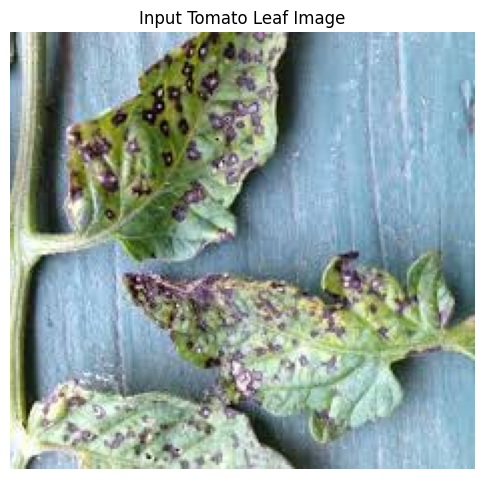



       TOMATO LEAF DISEASE RESULT
Predicted Disease : A tomato leaf with Septoria Leaf Spot
Confidence        : 95.75%

Top 3 Predictions:
------------------------------------------
1. A tomato leaf with Septoria Leaf Spot --> 95.75%
2. A tomato leaf with Early Blight --> 3.49%
3. A tomato leaf with Bacterial Spot --> 0.11%


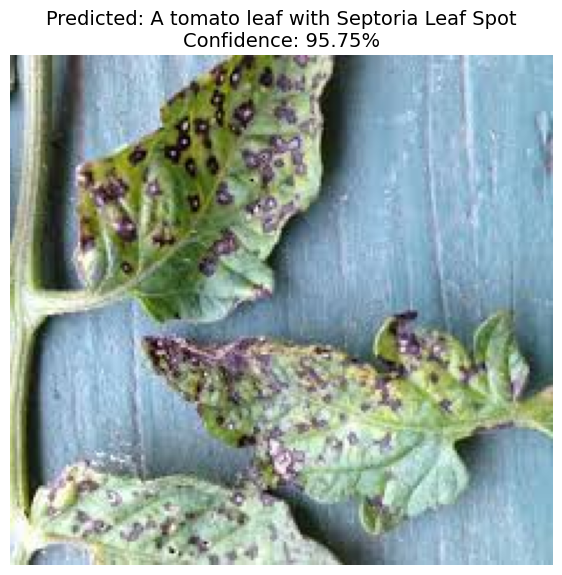

In [1]:
!pip install -q transformers torch torchvision pillow matplotlib

import torch
from transformers import AutoImageProcessor, AutoModelForImageClassification
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

# ==========================================
# 1. MODEL
# ==========================================

MODEL_NAME = "wellCh4n/tomato-leaf-disease-classification-vit"

print("Loading model...")

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = AutoModelForImageClassification.from_pretrained(MODEL_NAME)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)

# ==========================================
# 2. UPLOAD IMAGE
# ==========================================

print("\nUpload a tomato leaf image:")

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

# ==========================================
# 3. DISPLAY INPUT
# ==========================================

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Input Tomato Leaf Image")
plt.show()

# ==========================================
# 4. PREPROCESS IMAGE
# ==========================================

inputs = processor(
    images=image,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# ==========================================
# 5. PREDICTION
# ==========================================

with torch.no_grad():
    outputs = model(**inputs)

probabilities = torch.softmax(
    outputs.logits,
    dim=-1
)

confidence, predicted_class = torch.max(
    probabilities,
    dim=1
)

predicted_class = predicted_class.item()
confidence = confidence.item()

disease_name = model.config.id2label[predicted_class]

# ==========================================
# 6. RESULT
# ==========================================

print("\n")
print("==========================================")
print("       TOMATO LEAF DISEASE RESULT")
print("==========================================")
print("Predicted Disease :", disease_name)
print("Confidence        :", f"{confidence * 100:.2f}%")
print("==========================================")

# ==========================================
# 7. TOP 3 PREDICTIONS
# ==========================================

top_probs, top_indices = torch.topk(
    probabilities[0], 3
)

print("\nTop 3 Predictions:")
print("------------------------------------------")

for i in range(3):

    class_id = top_indices[i].item()
    probability = top_probs[i].item()

    print(
        f"{i+1}. "
        f"{model.config.id2label[class_id]} "
        f"--> {probability * 100:.2f}%"
    )

# ==========================================
# 8. DISPLAY FINAL RESULT
# ==========================================

plt.figure(figsize=(7, 7))
plt.imshow(image)
plt.axis("off")

plt.title(
    f"Predicted: {disease_name}\n"
    f"Confidence: {confidence * 100:.2f}%",
    fontsize=14
)

plt.show()